(hospital_length_of_stay)=
# Real-time Hospital Length of Stay with a Censored Gamma Model

:::{post} November, 2026
:tags: censored, survival analysis, hierarchical model, forecasting
:category: intermediate, tutorial
:author: Andres Hernandez
:::

Hospitals need length-of-stay estimates while an outbreak is growing. Many patients are still in hospital: we know only that their total stay exceeds the time observed. These stays are _right-censored_.

Averaging completed stays underestimates the mean because longer stays are more likely to be unfinished, as {cite:t}`vekaria2021hospital` discuss for COVID-19 in England.

We simulate a wave across 30 hospitals, fit a hierarchical Gamma model with {class}`~pymc.Censored`, and forecast beds occupied by today's patients over two weeks. We then adapt the likelihood to COVID-19 stays recorded in whole days in New York's 2024 SPARCS data.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt

from scipy import stats
from scipy.optimize import brentq
from scipy.special import gamma as gamma_fn
from scipy.special import gammaincc

In [2]:
%config InlineBackend.figure_format = 'retina'
RANDOM_SEED = 2026
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")

## Simulating a growing wave

Admissions grow by 5% daily, roughly doubling every two weeks. We analyse the wave on day 60. Hospitals vary in size; Gamma-distributed stays have hospital-specific shapes and means that depend on hospital and age group. Older patients stay longer.

A patient admitted at $t_i$ has been observed for $e_i = 60 - t_i$ days. If their total stay $T_i$ exceeds $e_i$, we record only $e_i$.

In [3]:
n_hospitals = 30
n_patients = 3000
growth = 0.05  # per day
analysis_day = 60.0
age_groups = ["<50", "50-69", "70+"]

hospital_size = rng.lognormal(0.0, 0.8, n_hospitals)
hospital_idx = rng.choice(n_hospitals, n_patients, p=hospital_size / hospital_size.sum())
age_idx = rng.choice(3, n_patients, p=[0.3, 0.35, 0.35])

# admission times from the exponential growth curve, by inverse transform sampling
quantile = rng.uniform(size=n_patients)
admitted = np.log1p(quantile * np.expm1(growth * analysis_day)) / growth

# true parameters: log mean stay per hospital, shape per hospital, age effects
true_log_mean = np.log(8.0) + 0.25 * rng.normal(size=n_hospitals)
true_shape = np.exp(np.log(2.5) + 0.3 * rng.normal(size=n_hospitals))
true_age_effect = np.array([0.0, 0.25, 0.45])

true_mean = np.exp(true_log_mean[hospital_idx] + true_age_effect[age_idx])
patient_shape = true_shape[hospital_idx]
true_stay = rng.gamma(patient_shape, true_mean / patient_shape)

elapsed = analysis_day - admitted
in_hospital = true_stay > elapsed
stay = np.where(in_hospital, elapsed, true_stay)

print(
    f"{n_patients} patients, {in_hospital.mean():.0%} still in hospital on day {analysis_day:.0f}"
)

3000 patients, 35% still in hospital on day 60


Most recent admissions are still in hospital. They lie on the line marking the time since admission, the longest stay observable so far.

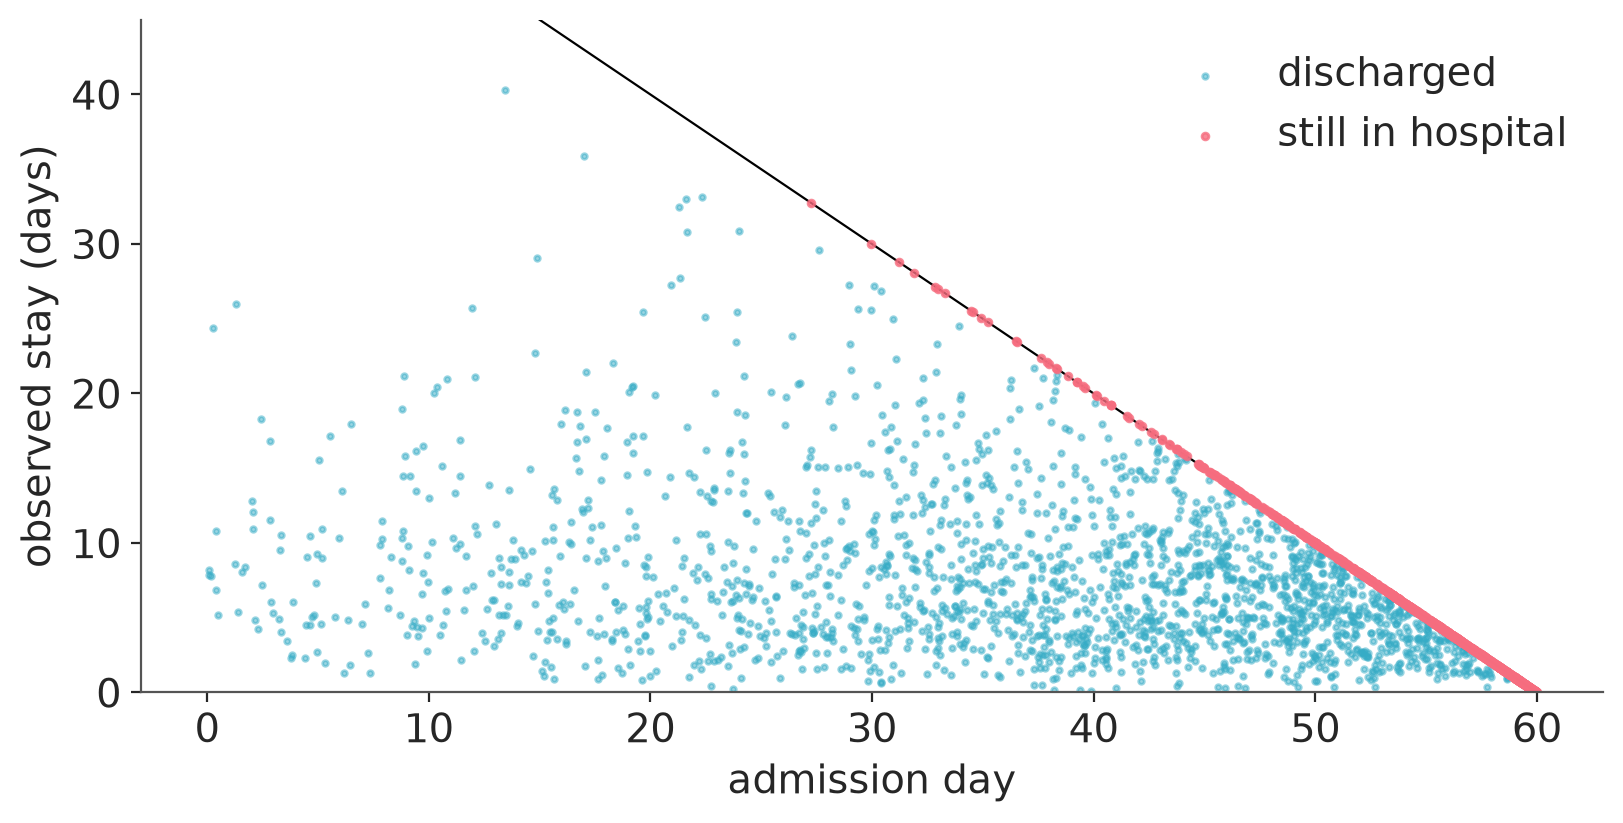

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot([0, analysis_day], [analysis_day, 0], color="k", lw=0.8, zorder=0)
ax.scatter(admitted[~in_hospital], stay[~in_hospital], s=4, alpha=0.5, label="discharged")
ax.scatter(admitted[in_hospital], stay[in_hospital], s=6, alpha=0.8, label="still in hospital")
ax.set(xlabel="admission day", ylabel="observed stay (days)", ylim=(0, 45))
ax.legend();

## Bias from completed stays

We compare the mean of completed stays with the true expected stay of all simulated patients in each age group.

In [5]:
for a, age_group in enumerate(age_groups):
    in_group = age_idx == a
    truth = true_mean[in_group].mean()
    naive = stay[in_group & ~in_hospital].mean()
    print(
        f"age {age_group:>5}: true mean stay {truth:5.1f} days, mean of completed stays {naive:5.1f} days "
        f"({naive / truth - 1:+.0%}), {in_hospital[in_group].mean():.0%} still in hospital"
    )

age   <50: true mean stay   7.2 days, mean of completed stays   5.9 days (-18%), 29% still in hospital
age 50-69: true mean stay   9.2 days, mean of completed stays   7.5 days (-18%), 34% still in hospital
age   70+: true mean stay  11.2 days, mean of completed stays   8.8 days (-22%), 41% still in hospital


Completed stays underestimate the mean by about a fifth. The bias is largest for older patients, whose longer stays are more often unfinished.

## Why a Gamma?

The Gamma offers two useful properties, though real data may favour alternatives such as the Weibull or log-normal.

With integer shape $k$, it describes $k$ successive exponential stages with the same rate. This connects latent-phase models of hospital stays {cite:p}`marshall2003conditional` to compartmental models through the linear chain trick {cite:p}`hurtado2019generalizations`. Rounding a shape $k \ge 1$ gives an approximate number of stages. Shapes below one imply greater relative variability than a single exponential stage and require another structure, such as parallel pathways.

Its _hazard_, the instantaneous discharge rate among patients still in hospital, approaches a constant. Below, we compare distributions with the same mean (8 days) and standard deviation: this Weibull's hazard keeps rising, while the log-normal's falls towards zero.

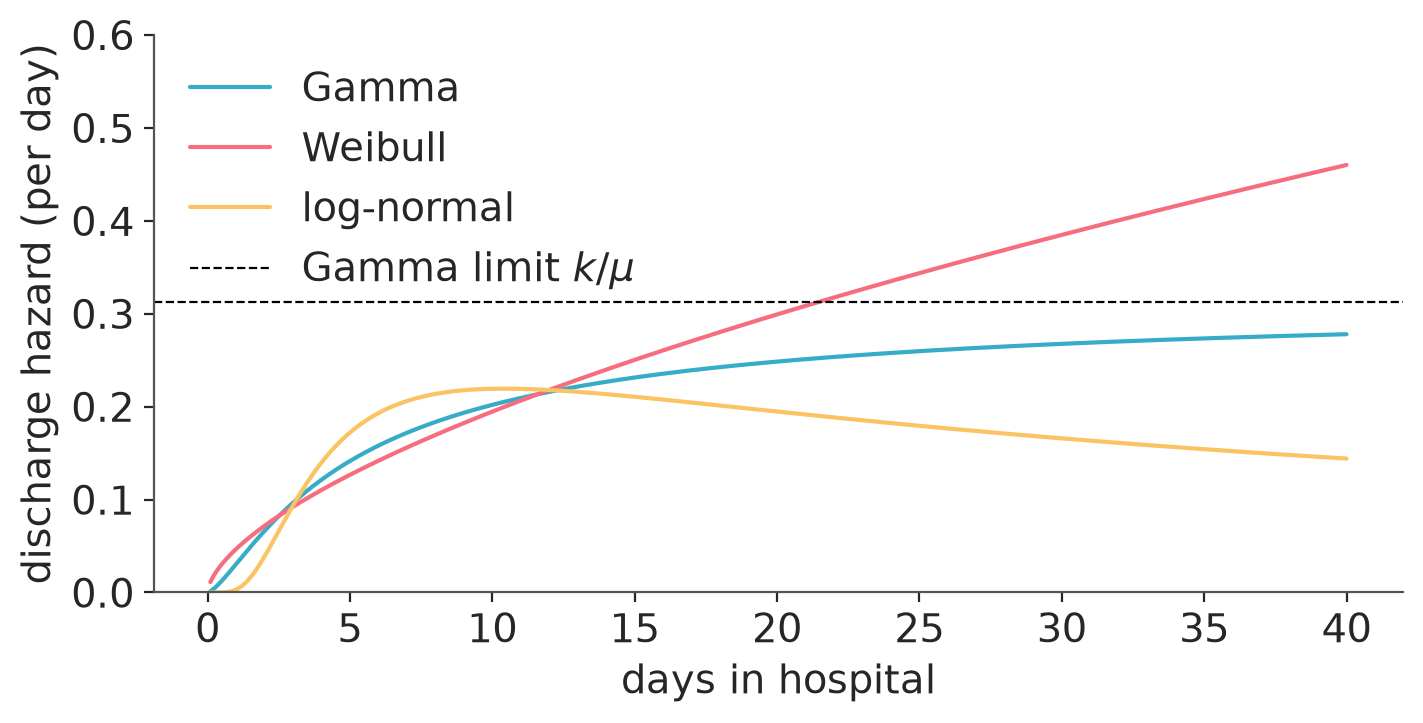

In [6]:
mean_stay, shape = 8.0, 2.5
coef_variation = 1 / np.sqrt(shape)


def weibull_coef_variation(weibull_shape):
    return np.sqrt(gamma_fn(1 + 2 / weibull_shape) / gamma_fn(1 + 1 / weibull_shape) ** 2 - 1)


weibull_shape = brentq(lambda c: weibull_coef_variation(c) - coef_variation, 0.5, 10)
log_variance = np.log1p(coef_variation**2)
dists = {
    "Gamma": stats.gamma(shape, scale=mean_stay / shape),
    "Weibull": stats.weibull_min(weibull_shape, scale=mean_stay / gamma_fn(1 + 1 / weibull_shape)),
    "log-normal": stats.lognorm(np.sqrt(log_variance), scale=mean_stay * np.exp(-log_variance / 2)),
}
days_plot = np.linspace(0.1, 40, 400)
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, dist in dists.items():
    ax.plot(days_plot, dist.pdf(days_plot) / dist.sf(days_plot), label=name)
ax.axhline(shape / mean_stay, color="k", lw=0.8, ls="--", label=r"Gamma limit $k / \mu$")
ax.set(xlabel="days in hospital", ylabel="discharge hazard (per day)", ylim=(0, 0.6))
ax.legend();

## The model

We write the Gamma in terms of its mean $\mu$ and shape $k$, so that the rate is $k / \mu$:

$$
\begin{aligned}
T_i &\sim \text{Gamma}\left(k_{h[i]},\ k_{h[i]} / \mu_i\right) \\
\log \mu_i &= \alpha_{h[i]} + \beta_{a[i]}, \qquad \alpha_h = \mu_0 + \sigma_\mu z_{\mu, h} \\
\log k_h &= \kappa_0 + \sigma_k z_{k, h} \\
z_{\mu, h},\ z_{k, h} &\sim \text{Normal}(0, 1) \\
\mu_0 &\sim \text{Normal}(2, 0.5), \quad \kappa_0 \sim \text{Normal}(\log 2, 0.5) \\
\sigma_\mu,\ \sigma_k &\sim \text{HalfNormal}(0.5), \quad \beta_{\text{50-69}},\ \beta_{\text{70+}} \sim \text{Normal}(0, 0.5)
\end{aligned}
$$

Here $h[i]$ and $a[i]$ identify patient $i$'s hospital and age group. The hospital log mean $\alpha_h$ applies to patients under 50; $\beta_a$ is the age effect, with $\beta_{<50} = 0$. The hyperparameters pool hospital log means and shapes. Standardized deviations $z$ give a non-centered form, useful for hospitals with few patients.

Discharged patients contribute the Gamma density; unfinished stays contribute its survival function at $e_i$. With {class}`~pymc.Censored`, we pass $e_i$ as the upper bound: observations at the bound are censored, while shorter, completed stays retain their density.

We also fit completed stays alone to measure the resulting bias.

In [7]:
def build_model(censored):
    keep = np.ones(n_patients, dtype=bool) if censored else ~in_hospital
    coords = {
        "hospital": np.arange(n_hospitals),
        "age": age_groups,
        "older": age_groups[1:],
        "patient": np.flatnonzero(keep),
    }
    with pm.Model(coords=coords) as model:
        mu0 = pm.Normal("mu0", 2.0, 0.5)
        beta = pm.Normal("beta", 0.0, 0.5, dims="older")
        sigma_mu = pm.HalfNormal("sigma_mu", 0.5)
        z_mu = pm.Normal("z_mu", 0.0, 1.0, dims="hospital")
        kappa0 = pm.Normal("kappa0", np.log(2.0), 0.5)
        sigma_k = pm.HalfNormal("sigma_k", 0.5)
        z_k = pm.Normal("z_k", 0.0, 1.0, dims="hospital")

        alpha = pm.Deterministic("alpha", mu0 + sigma_mu * z_mu, dims="hospital")
        k = pm.Deterministic("k", pm.math.exp(kappa0 + sigma_k * z_k), dims="hospital")
        age_effect = pm.Deterministic("age_effect", pm.math.concatenate([[0.0], beta]), dims="age")

        mu = pm.math.exp(alpha[hospital_idx[keep]] + age_effect[age_idx[keep]])
        patient_k = k[hospital_idx[keep]]
        if censored:
            stay_dist = pm.Gamma.dist(alpha=patient_k, beta=patient_k / mu)
            pm.Censored("stay", stay_dist, lower=None, upper=elapsed, observed=stay, dims="patient")
        else:
            pm.Gamma(
                "stay", alpha=patient_k, beta=patient_k / mu, observed=stay[keep], dims="patient"
            )
    return model


censored_model = build_model(censored=True)
completed_model = build_model(censored=False)

## Fitting

In [8]:
def check_convergence(model, idata):
    var_names = [rv.name for rv in model.free_RVs]
    assert (az.summary(idata, var_names=var_names)["r_hat"] < 1.03).all()
    assert int(idata.sample_stats["diverging"].sum()) == 0


with censored_model:
    censored_idata = pm.sample(random_seed=rng)
check_convergence(censored_model, censored_idata)

with completed_model:
    completed_idata = pm.sample(random_seed=rng)
check_convergence(completed_model, completed_idata)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu0, beta, sigma_mu, z_mu, kappa0, sigma_k, z_k]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 171 seconds.


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu0, beta, sigma_mu, z_mu, kappa0, sigma_k, z_k]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 18 seconds.


In [9]:
az.summary(censored_idata, var_names=["mu0", "beta", "sigma_mu", "kappa0", "sigma_k"])

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu0,1.965,0.049,1.9,2,1235,1733,1.00,0.0014,0.0008
beta[50-69],0.2638,0.0337,0.21,0.32,5637,3361,1.00,0.00045,0.0005
beta[70+],0.4958,0.034,0.44,0.55,5860,3484,1.00,0.00044,0.00051
sigma_mu,0.227,0.036,0.18,0.29,1401,1816,1.00,0.00095,0.00057
kappa0,0.952,0.067,0.85,1.1,1598,2101,1.00,0.0017,0.0011
sigma_k,0.321,0.06,0.24,0.43,1664,2496,1.00,0.0015,0.001


## Recovering the simulation

We compare each hospital's {term}`posterior` with the true value. The diagonal marks perfect recovery; bars show 90% intervals.

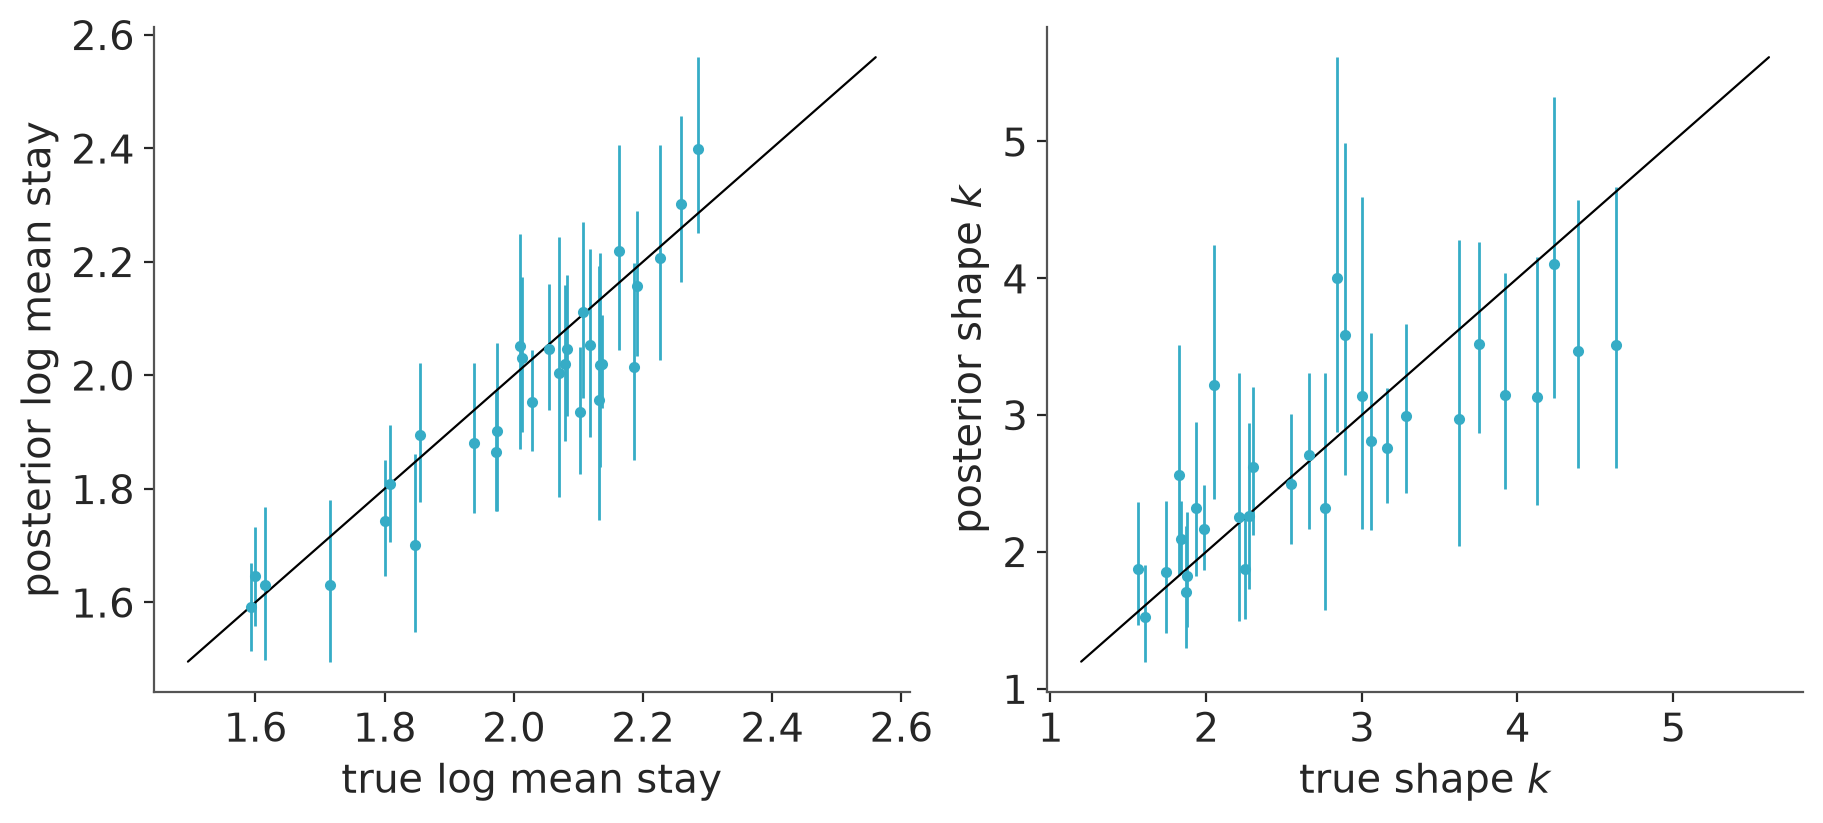

In [10]:
censored_post = az.extract(censored_idata)
completed_post = az.extract(completed_idata)

fig, axs = plt.subplots(1, 2, figsize=(9, 4))
for ax, var, truth, label in [
    (axs[0], "alpha", true_log_mean, "log mean stay"),
    (axs[1], "k", true_shape, "shape $k$"),
]:
    draws = censored_post[var].values
    lo, mid, hi = np.percentile(draws, [5, 50, 95], axis=-1)
    ax.errorbar(truth, mid, yerr=[mid - lo, hi - mid], fmt="o", ms=3, lw=1)
    lims = [min(truth.min(), lo.min()), max(truth.max(), hi.max())]
    ax.plot(lims, lims, color="k", lw=0.8)
    ax.set(xlabel=f"true {label}", ylabel=f"posterior {label}");

The censored model also recovers the age effects. Using only completed stays underestimates them, especially for the oldest patients.

In [11]:
fits = [("censored", censored_post), ("completed only", completed_post)]
for name, post in fits:
    lo, hi = np.percentile(post["beta"].values, [5, 95], axis=-1)
    print(f"{name:>14}: 50-69 [{lo[0]:.2f}, {hi[0]:.2f}], 70+ [{lo[1]:.2f}, {hi[1]:.2f}]")
print(f"{'true':>14}: 50-69 {true_age_effect[1]:.2f}, 70+ {true_age_effect[2]:.2f}")

      censored: 50-69 [0.21, 0.32], 70+ [0.44, 0.55]
completed only: 50-69 [0.18, 0.29], 70+ [0.35, 0.47]
          true: 50-69 0.25, 70+ 0.45


For each posterior draw, we average expected stays over the patients in each age group. We compare these estimates with the true means and the averages of completed stays.

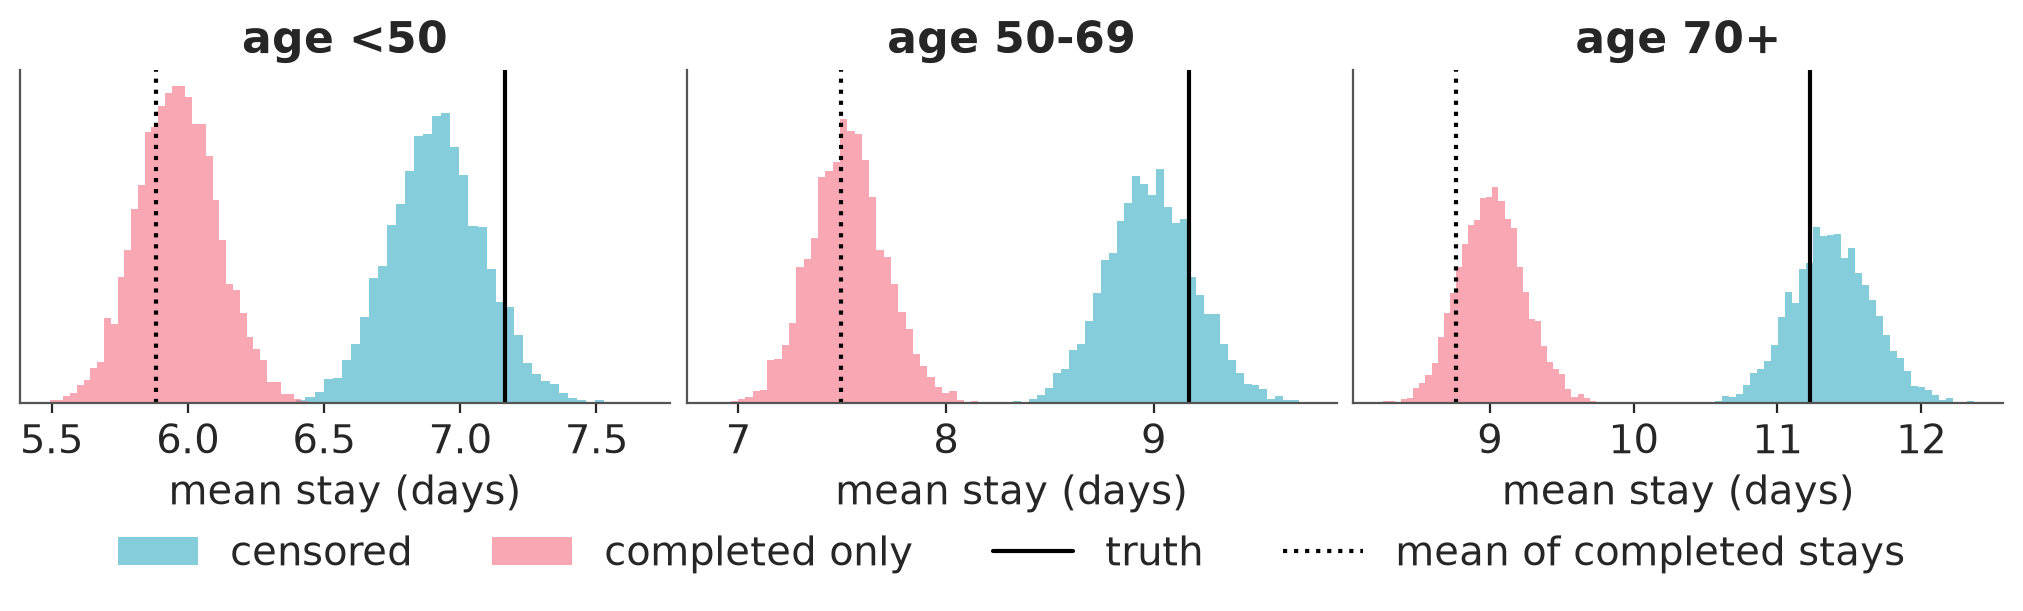

In [12]:
def mean_stay_by_age(post):
    mu = np.exp(post["alpha"].values[hospital_idx] + post["age_effect"].values[age_idx])
    return [mu[age_idx == a].mean(axis=0) for a in range(len(age_groups))]


fig, axs = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for a, age_group in enumerate(age_groups):
    ax = axs[a]
    in_group = age_idx == a
    for name, post in fits:
        ax.hist(mean_stay_by_age(post)[a], bins=40, density=True, alpha=0.6, label=name)
    ax.axvline(true_mean[in_group].mean(), color="k", label="truth")
    ax.axvline(
        stay[in_group & ~in_hospital].mean(), color="k", ls=":", label="mean of completed stays"
    )
    ax.set(title=f"age {age_group}", xlabel="mean stay (days)", yticks=[])
fig.legend(*axs[0].get_legend_handles_labels(), loc="outside lower center", ncols=4);

## Forecasting today's beds

For a patient still in hospital after $e_i$ days, total stay follows the Gamma truncated below at $e_i$. Remaining stay is $T_i - e_i$. We draw it with {class}`~pymc.Truncated` and count patients remaining after each forecast day.

We check the forecast against the simulation. It covers only today's patients; future admissions would require a separate model.

In [13]:
inpatient_idx = np.flatnonzero(in_hospital)
print(f"{len(inpatient_idx)} patients in hospital on day {analysis_day:.0f}")
horizon = np.arange(15)
actual = np.array([(true_stay[inpatient_idx] - elapsed[inpatient_idx] > s).sum() for s in horizon])


def forecast(model, idata):
    with model:
        model.add_coord("inpatient", inpatient_idx)
        mu = pm.math.exp(
            model["alpha"][hospital_idx[inpatient_idx]]
            + model["age_effect"][age_idx[inpatient_idx]]
        )
        inpatient_k = model["k"][hospital_idx[inpatient_idx]]
        pm.Truncated(
            "total_stay",
            pm.Gamma.dist(alpha=inpatient_k, beta=inpatient_k / mu),
            lower=elapsed[inpatient_idx],
            dims="inpatient",
        )
        post_pred = pm.sample_posterior_predictive(idata, var_names=["total_stay"], random_seed=rng)
    total = post_pred.posterior_predictive["total_stay"].stack(sample=("chain", "draw")).values
    remaining = total - elapsed[inpatient_idx][:, None]
    return np.stack([(remaining > s).sum(axis=0) for s in horizon], axis=1)


beds = {
    "censored": forecast(censored_model, censored_idata),
    "completed only": forecast(completed_model, completed_idata),
}

1055 patients in hospital on day 60


Sampling: [total_stay]


Output()

Sampling: [total_stay]


Output()

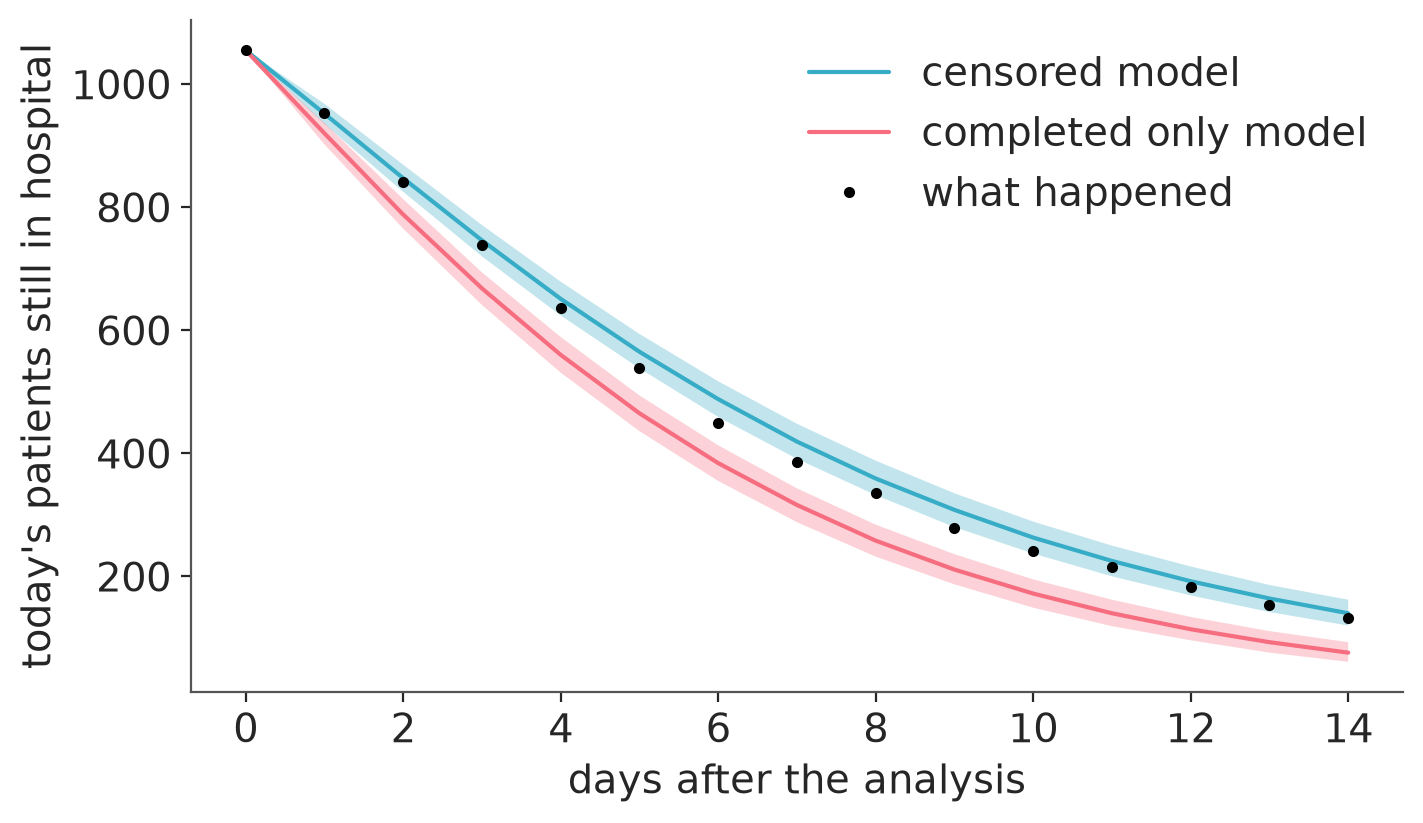

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, model_beds in beds.items():
    lo, mid, hi = np.percentile(model_beds, [5, 50, 95], axis=0)
    ax.fill_between(horizon, lo, hi, alpha=0.3)
    ax.plot(horizon, mid, label=f"{name} model")
ax.plot(horizon, actual, "k.", label="what happened")
ax.set(xlabel="days after the analysis", ylabel="today's patients still in hospital")
ax.legend();

In [15]:
for name, model_beds in beds.items():
    lo, mid, hi = np.percentile(model_beds[:, 14], [5, 50, 95])
    print(f"{name:>14}: day 14 forecast {mid:.0f} beds (90% interval {lo:.0f}-{hi:.0f})")
print(f"{'actual':>14}: {actual[14]} beds")

      censored: day 14 forecast 140 beds (90% interval 120-162)
completed only: day 14 forecast 76 beds (90% interval 61-93)
        actual: 133 beds


The censored model's 90% interval contains the actual count after two weeks. The model using completed stays predicts little more than half the beds needed.

## Real stays: COVID-19 in New York, 2024

We use COVID-19 discharges from New York's Statewide Planning and Research Cooperative System (SPARCS) {cite:p}`nysdoh2025sparcs`. Each row is a stay ending in 2024 with COVID-19 as the principal diagnosis. We retain hospital, age group, illness severity and recorded length of stay.

:::{note}
The raw SPARCS data used to produce this publication was provided by the New York State Department of Health. However, the calculations, metrics, conclusions derived, and views expressed herein are those of the author(s) and do not reflect the work, conclusions, or views of New York State. The New York State Department of Health, its employees, officers, and agents make no representation, warranty or guarantee as to the accuracy, completeness, currency, or suitability of the information provided here.
:::

:::{dropdown} How the data file was made
We select the COVID-19 diagnosis category (`INF012`) from Health Data NY's 2024 de-identified SPARCS dataset (`sf4k-39ay`):

```python
from urllib.parse import urlencode

query = {
    "$select": "permanent_facility_id, age_group, apr_severity_of_illness_code, length_of_stay",
    "$where": "ccsr_diagnosis_code = 'INF012'",
    "$order": ":id",
    "$limit": 100_000,
}
records = pd.read_csv(
    "https://health.data.ny.gov/resource/sf4k-39ay.csv?" + urlencode(query), dtype=str
)
```

The rows were then sorted by these four columns.
:::

In [16]:
try:
    records = pd.read_csv(
        "../data/sparcs_2024_covid19_stays.csv", dtype={"permanent_facility_id": str}
    )
except FileNotFoundError:
    records = pd.read_csv(
        pm.get_data("sparcs_2024_covid19_stays.csv"), dtype={"permanent_facility_id": str}
    )
print(f"{len(records)} stays")

18290 stays


These are completed stays; censoring comes from their recording. The 2024 data dictionary defines length of stay as discharge date minus admission date plus one, with values of 120 or more coded as "120+". Admission and discharge times are unavailable. Assuming admission at midday, a recorded stay of $d$ days corresponds to $[\max(0, d - 1.5), d - 0.5)$ days; "120+" corresponds to at least 118.5 days. We therefore use interval and right censoring.

Almost all stays have "major" or "extreme" severity. We use the five age groups and two severity levels: extreme or not. Following SPARCS's publication guidelines, we retain hospitals with more than ten COVID-19 stays and display only counts above ten.

We aggregate identical hospital, group and recorded-stay combinations into counts, reducing the likelihood to a few thousand rows.

In [17]:
covid = records.dropna(subset=["permanent_facility_id"])  # a few stays have the hospital redacted
covid = covid[covid.groupby("permanent_facility_id")["age_group"].transform("size") > 10].copy()
covid["days"] = covid["length_of_stay"].replace("120+", "120").astype(int)
covid["severity"] = np.where(covid["apr_severity_of_illness_code"] == 4, "extreme", "up to major")
print(f"{len(covid)} stays in {covid['permanent_facility_id'].nunique()} hospitals")

stay_counts = (
    covid.groupby(["permanent_facility_id", "age_group", "severity", "days"])
    .size()
    .rename("n")
    .reset_index()
)
print(f"{len(stay_counts)} combinations of hospital, age group, severity and recorded days")
pd.crosstab(covid["age_group"], covid["severity"])

18181 stays in 164 hospitals
6252 combinations of hospital, age group, severity and recorded days


severity,extreme,up to major
age_group,,
0-17,76,899
18-29,27,248
30-49,121,767
50-69,791,3169
70 or Older,2283,9800


### The model for recorded stays

Each age–severity group has its own mean and shape, pooled across groups. Each hospital multiplies the mean by a common factor:

$$
\begin{aligned}
T &\sim \text{Gamma}\left(k_g,\ k_g / \mu_{g, h}\right) \\
\log \mu_{g, h} &= m_g + \eta_h, \qquad m_g \sim \text{Normal}(\mu_0, \sigma_\mu), \quad \eta_h \sim \text{Normal}(0, \sigma_h) \\
\log k_g &\sim \text{Normal}(\kappa_0, \sigma_k) \\
\mu_0 &\sim \text{Normal}(1.5, 1), \quad \kappa_0 \sim \text{Normal}(0, 1), \quad \sigma_\mu,\ \sigma_h,\ \sigma_k \sim \text{HalfNormal}(1)
\end{aligned}
$$

Here $m_g$ is group $g$'s log mean at a typical hospital, $k_g$ its shape, and $\exp(\eta_h)$ hospital $h$'s factor. The hyperparameters control variation across groups and hospitals. With more data per effect, we use a centered parameterization.

For $n$ stays in an interval $[\ell, u)$, the {term}`likelihood` contribution is $n \log \Pr(\ell \le T < u)$, as in {ref}`awkward_binning`. With rate $\beta = k / \mu$, the interval probability is a difference of Gamma cumulative distribution functions (CDFs):

$$
P(k, \beta u) - P(k, \beta \ell),
$$

where $P$ is the regularized lower incomplete gamma function. Above the median recorded stay, we instead use $Q(k, \beta \ell) - Q(k, \beta u)$, with $Q = 1 - P$, to avoid subtracting CDF values close to one. For top-coded stays the probability is $Q(k, \beta \ell)$; the first interval starts at zero.

We implement these probabilities with PyTensor's `gammainc` ($P$) and `gammaincc` ($Q$), adding the log likelihood through {func}`~pymc.Potential`. For comparison, we also fit the Gamma density at each recorded day $d$, treating it as exact.

In [18]:
ny_ages = ["0-17", "18-29", "30-49", "50-69", "70 or Older"]
ny_severities = ["up to major", "extreme"]
ny_groups = [f"{age}, {severity}" for age in ny_ages for severity in ny_severities]
group_idx = (
    stay_counts["age_group"].map(ny_ages.index).to_numpy() * 2
    + stay_counts["severity"].map(ny_severities.index).to_numpy()
)
hospital_ids, ny_hospital_idx = np.unique(stay_counts["permanent_facility_id"], return_inverse=True)
days = stay_counts["days"].to_numpy(dtype=float)
n_stays = stay_counts["n"].to_numpy(dtype=float)

# each recorded stay of d days lasted between d - 1.5 and d - 0.5 days
interval_start = np.maximum(days - 1.5, 0.0)
interval_end = days - 0.5
median_days = np.median(covid["days"])
first_day = np.flatnonzero(days == 1)
top_coded = np.flatnonzero(days == 120)
below_median = np.flatnonzero((days > 1) & (days < 120) & (days <= median_days))
above_median = np.flatnonzero((days > 1) & (days < 120) & (days > median_days))


def build_ny_model(interval):
    with pm.Model(coords={"group": ny_groups, "hospital": hospital_ids}) as model:
        mu0 = pm.Normal("mu0", 1.5, 1.0)
        sigma_mu = pm.HalfNormal("sigma_mu", 1.0)
        m = pm.Normal("m", mu0, sigma_mu, dims="group")
        sigma_h = pm.HalfNormal("sigma_h", 1.0)
        eta = pm.Normal("eta", 0.0, sigma_h, dims="hospital")
        kappa0 = pm.Normal("kappa0", 0.0, 1.0)
        sigma_k = pm.HalfNormal("sigma_k", 1.0)
        log_k = pm.Normal("log_k", kappa0, sigma_k, dims="group")

        group_mean = pm.Deterministic("group_mean", pm.math.exp(m), dims="group")
        hospital_effect = pm.Deterministic("hospital_effect", pm.math.exp(eta), dims="hospital")
        k = pm.Deterministic("k", pm.math.exp(log_k), dims="group")

        shape = k[group_idx]
        rate = shape / (group_mean[group_idx] * hospital_effect[ny_hospital_idx])
        if interval:

            def cdf(rows, t):
                return pt.gammainc(shape[rows], rate[rows] * t[rows])

            def survival(rows, t):
                return pt.gammaincc(shape[rows], rate[rows] * t[rows])

            log_prob = [
                (first_day, pt.log(cdf(first_day, interval_end))),
                (
                    below_median,
                    pt.log(cdf(below_median, interval_end) - cdf(below_median, interval_start)),
                ),
                (
                    above_median,
                    pt.log(
                        survival(above_median, interval_start)
                        - survival(above_median, interval_end)
                    ),
                ),
                (top_coded, pt.log(survival(top_coded, interval_start))),
            ]
            loglik = sum((n_stays[rows] * lp).sum() for rows, lp in log_prob)
        else:
            gamma = pm.Gamma.dist(alpha=shape, beta=rate)
            loglik = (n_stays * pm.logp(gamma, days)).sum()
        pm.Potential("stays", loglik)
    return model


interval_model = build_ny_model(interval=True)
exact_model = build_ny_model(interval=False)

In [19]:
with interval_model:
    interval_idata = pm.sample(random_seed=rng)
check_convergence(interval_model, interval_idata)

with exact_model:
    exact_idata = pm.sample(random_seed=rng)
check_convergence(exact_model, exact_idata)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu0, sigma_mu, m, sigma_h, eta, kappa0, sigma_k, log_k]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 390 seconds.


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu0, sigma_mu, m, sigma_h, eta, kappa0, sigma_k, log_k]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 25 seconds.


In [20]:
az.summary(interval_idata, var_names=["mu0", "sigma_mu", "sigma_h", "kappa0", "sigma_k"])

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu0,1.635,0.22,1.3,2,4864,2737,1.00,0.0033,0.005
sigma_mu,0.701,0.177,0.47,1,5402,2888,1.00,0.0027,0.0036
sigma_h,0.2732,0.019,0.24,0.3,4469,3316,1.00,0.00028,0.00029
kappa0,-0.096,0.117,-0.28,0.089,4936,2885,1.00,0.0017,0.0023
sigma_k,0.342,0.098,0.22,0.51,4796,2869,1.00,0.0016,0.0026


### Effect of recording whole days

We compare each group's mean at a typical hospital (effect 1) and shape $k$, with 90% intervals.

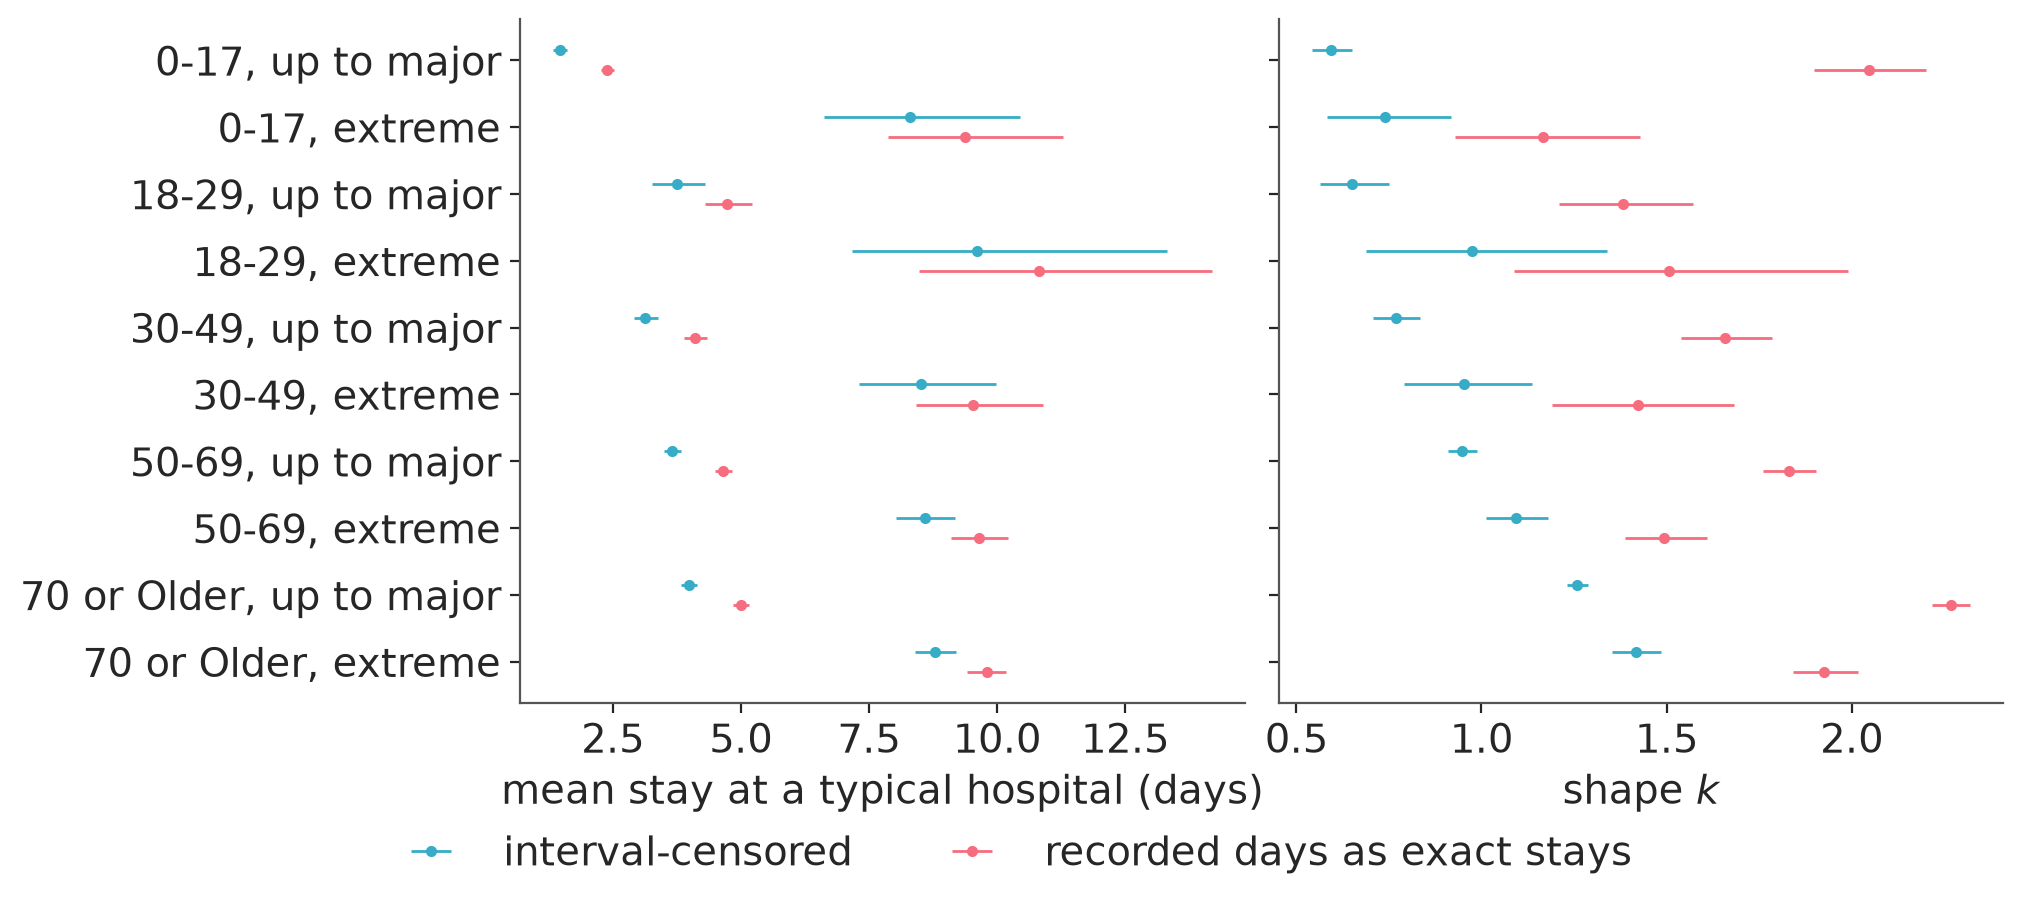

In [21]:
interval_post = az.extract(interval_idata)
exact_post = az.extract(exact_idata)
ny_fits = [("interval-censored", interval_post), ("recorded days as exact stays", exact_post)]

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
y = np.arange(len(ny_groups))
for ax, var, label in [
    (axs[0], "group_mean", "mean stay at a typical hospital (days)"),
    (axs[1], "k", "shape $k$"),
]:
    for offset, (name, post) in zip([-0.15, 0.15], ny_fits):
        q05, q50, q95 = np.percentile(post[var].values, [5, 50, 95], axis=-1)
        ax.errorbar(q50, y + offset, xerr=[q50 - q05, q95 - q50], fmt="o", ms=3, lw=1, label=name)
    ax.set(xlabel=label)
axs[0].set(yticks=y, yticklabels=ny_groups)
axs[0].invert_yaxis()
fig.legend(*axs[1].get_legend_handles_labels(), loc="outside lower center", ncols=2);

In [22]:
pd.DataFrame(
    {
        f"{var}, {name}": np.median(post[var].values, axis=-1)
        for var in ["group_mean", "k"]
        for name, post in [("interval", interval_post), ("exact", exact_post)]
    },
    index=ny_groups,
).round(2)

,"group_mean, interval","group_mean, exact","k, interval","k, exact"
"0-17, up to major",1.47,2.39,0.59,2.05
"0-17, extreme",8.30,9.38,0.74,1.17
"18-29, up to major",3.76,4.73,0.65,1.38
"18-29, extreme",9.61,10.81,0.97,1.51
"30-49, up to major",3.14,4.11,0.77,1.66
"30-49, extreme",8.53,9.53,0.95,1.42
"50-69, up to major",3.66,4.66,0.95,1.83
"50-69, extreme",8.59,9.64,1.09,1.49
"70 or Older, up to major",3.99,5.00,1.26,2.27
"70 or Older, extreme",8.78,9.80,1.42,1.93


Treating recorded days as exact raises fitted means by 0.9–1.2 days and shapes by a factor of 1.4–3.5. The shape changes most for younger patients with short stays. Under the midday-admission assumption, recorded $d$ represents roughly $d - 1$ elapsed days, explaining the shift in means.

Interval-model shapes range from 0.6 to 1.4, with posterior medians below one in seven groups. Those groups have greater relative variability than an exponential, which a chain of successive exponential stages cannot reproduce. The exact-days fit instead gives shapes of 1.2–2.3, suggesting a different compartment structure.

### Does the model reproduce the recorded stays?

We compare the observed share recorded as staying longer than $d$ days with predictions averaged over each group's hospital mix. This corresponds to $T \ge d - 0.5$ in the interval model and $T > d$ in the exact-days model. Curves stop when fewer than eleven observed stays remain.

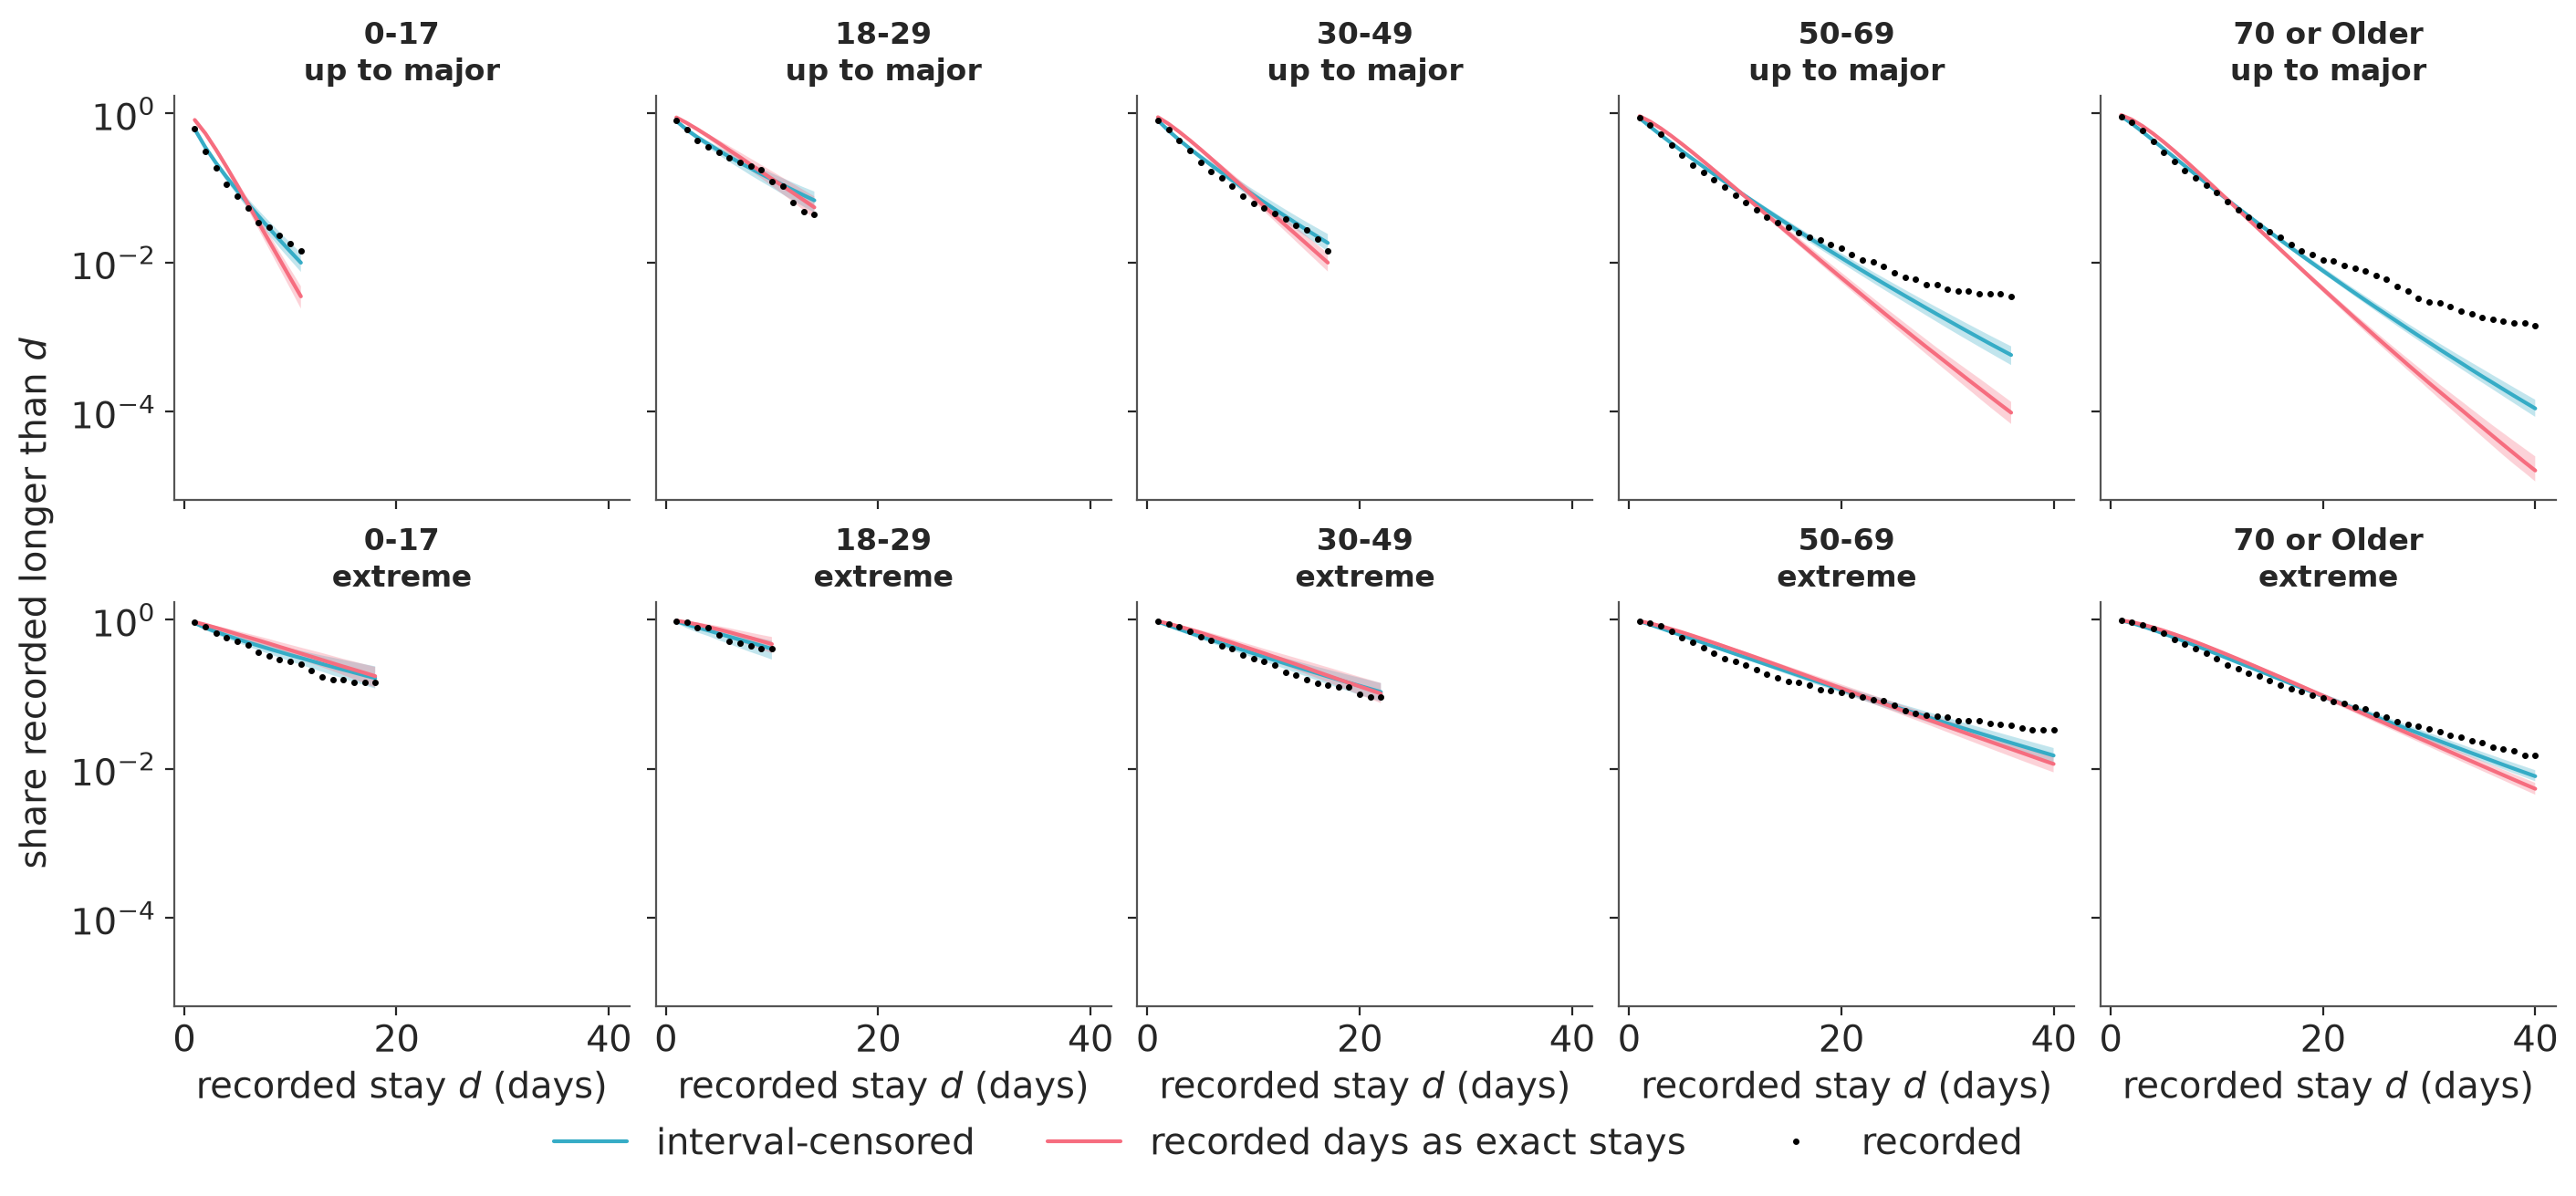

In [23]:
def recorded_longer_than(post, g, d, offset, draws=200):
    """Share of group g's stays recorded as longer than d days, per posterior draw."""
    in_group = group_idx == g
    weight = np.bincount(ny_hospital_idx[in_group], n_stays[in_group], minlength=len(hospital_ids))
    draw_idx = np.linspace(0, post.sizes["sample"] - 1, draws).astype(int)
    k = post["k"].values[g, draw_idx]
    mean = post["group_mean"].values[g, draw_idx] * post["hospital_effect"].values[:, draw_idx]
    share = gammaincc(k[None, :, None], k[None, :, None] / mean[:, :, None] * (d - offset))
    return np.einsum("h,hsd->sd", weight / weight.sum(), share)


d_grid = np.arange(1, 41)
fig, axs = plt.subplots(2, 5, figsize=(14, 6.5), sharex=True, sharey=True)
for g, ax in enumerate(axs.T.ravel()):
    in_group = group_idx == g
    longer = np.array([n_stays[in_group & (days > d)].sum() for d in d_grid])
    shown = longer > 10
    for (name, post), offset in zip(ny_fits, [0.5, 0.0]):
        q05, q50, q95 = np.percentile(
            recorded_longer_than(post, g, d_grid, offset), [5, 50, 95], axis=0
        )
        ax.fill_between(d_grid[shown], q05[shown], q95[shown], alpha=0.3)
        ax.plot(d_grid[shown], q50[shown], label=name)
    ax.plot(d_grid[shown], longer[shown] / n_stays[in_group].sum(), "k.", ms=3, label="recorded")
    ax.set_title(ny_groups[g].replace(", ", "\n"), fontsize="medium")
    ax.set(yscale="log")
for ax in axs[1]:
    ax.set(xlabel="recorded stay $d$ (days)")
fig.supylabel("share recorded longer than $d$")
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="outside lower center", ncols=3);

In [24]:
older_group = ny_groups.index("70 or Older, up to major")
in_group = group_idx == older_group
for d in [7, 14, 28]:
    recorded = n_stays[in_group & (days > d)].sum() / n_stays[in_group].sum()
    predicted = [
        np.median(recorded_longer_than(post, older_group, np.array([d]), offset))
        for (name, post), offset in zip(ny_fits, [0.5, 0.0])
    ]
    print(
        f"longer than {d:2d} days: recorded {recorded:.2%}, "
        f"interval-censored {predicted[0]:.2%}, exact days {predicted[1]:.2%}"
    )

longer than  7 days: recorded 17.05%, interval-censored 19.70%, exact days 23.49%
longer than 14 days: recorded 3.13%, interval-censored 3.26%, exact days 2.76%
longer than 28 days: recorded 0.42%, interval-censored 0.13%, exact days 0.04%


The interval model follows the recorded stays reasonably well for two weeks and improves the fit to short stays, especially for children. Both models underpredict longer stays in the two largest groups, ages 50–69 and 70+ without extreme severity. For the latter, 0.42% of stays exceed four recorded weeks, compared with predictions of 0.13% and 0.04% from the interval and exact-days models.

A mixture of short- and long-stay Gammas could improve this tail fit. Its interval likelihood would use the mixture's CDF and survival function.

### Hospitals

Hospital effects on mean stay, with 90% intervals, plotted against the number of COVID-19 stays:

middle 90% of hospitals: 0.72 to 1.53 times the stay at a typical hospital


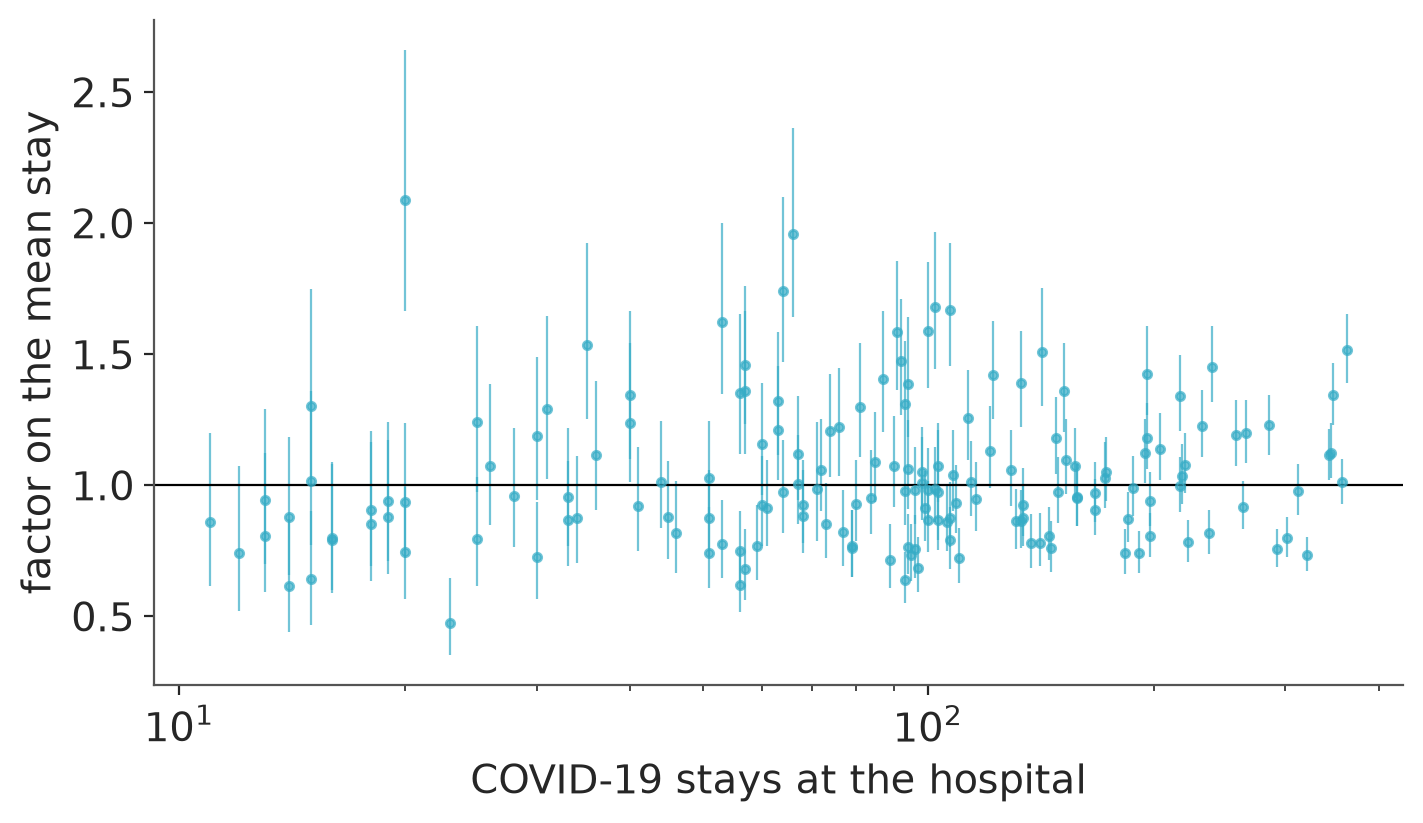

In [25]:
stays_per_hospital = np.bincount(ny_hospital_idx, n_stays)
q05, q50, q95 = np.percentile(interval_post["hospital_effect"].values, [5, 50, 95], axis=-1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(stays_per_hospital, q50, yerr=[q50 - q05, q95 - q50], fmt="o", ms=3, lw=0.8, alpha=0.7)
ax.axhline(1.0, color="k", lw=0.8)
ax.set(xscale="log", xlabel="COVID-19 stays at the hospital", ylabel="factor on the mean stay")
print(
    f"middle 90% of hospitals: {np.percentile(q50, 5):.2f} to {np.percentile(q50, 95):.2f} "
    "times the stay at a typical hospital"
)

After adjustment for age and severity, the middle 90% of estimated hospital factors span 0.72–1.53. Hospitals with few stays have wider intervals and estimates pooled towards 1.

## Summary

- Including unfinished stays through the survival function avoids the bias from analysing completed stays alone. In this simulation, that shortcut underestimated mean stays by about a fifth and the two-week bed forecast by over 40%.
- Partial pooling estimates hospital effects even where data are sparse.
- Whole-day recording needs an interval likelihood. Here, treating recorded days as exact inflated means and shapes; neither Gamma model captured the longest stays well.

Extensions include comparing lifetime distributions, allowing stays to change over time, and combining whole-day intervals with censoring during an ongoing wave.

## References

:::{bibliography}
:filter: docname in docnames
:::

## Authors

- Authored by [Andres Hernandez](https://github.com/andreshernandez-spec) in November 2026 ([pymc-examples#914](https://github.com/pymc-devs/pymc-examples/pull/914))

## Watermark

In [26]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pytensor,xarray

Last updated: Tue, 17 Nov 2026

Python implementation: CPython
Python version       : 3.13.14
IPython version      : 9.18.1

pytensor: 3.3.7
xarray  : 2026.9.0

IPython   : 9.18.1
arviz     : 1.3.0
matplotlib: 3.11.2
numpy     : 2.5.4
pandas    : 3.1.1
pymc      : 6.4.0
pytensor  : 3.3.7
scipy     : 1.18.1

Watermark: 2.6.0



:::{include} ../page_footer.md
:::